In [1]:
from foundations.linalg.vector_ops import dot, l2_norm, scalar_projection, vector_projection

a, b = [3.0, 4.0], [2.0, 0.0]
print(scalar_projection(a, b), scalar_projection(b, a))
print(vector_projection(a, b))  

3.0 1.2
[3.0, 0.0]


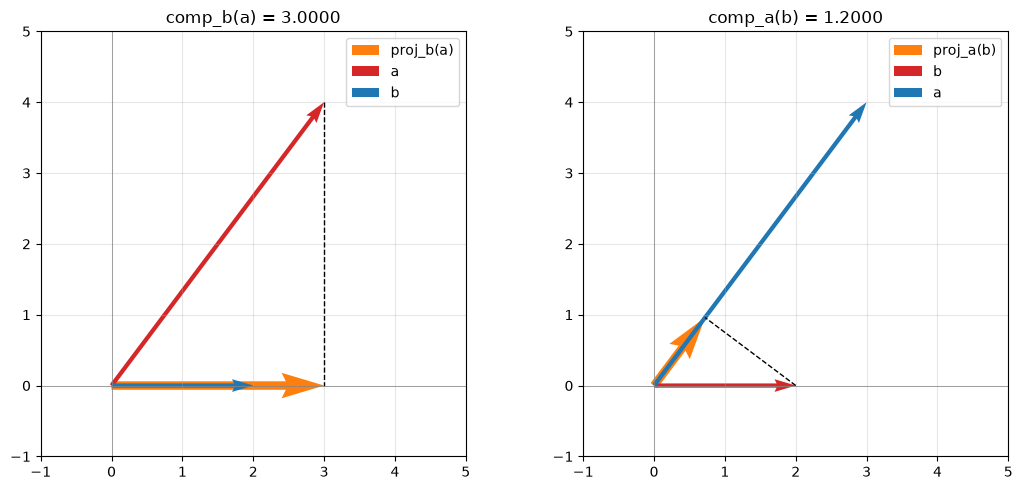

In [ ]:
import matplotlib.pyplot as plt

from foundations.linalg.vector_ops import scalar_projection, vector_projection                   


def plot_projection(ax, a, b, name_a, name_b):
    """Draw a, b and the shadow of a on the line through b."""
    p = vector_projection(a, b)  # the shadow, as a vector along b

    # angles/scale_units/scale make arrow lengths mean data units, not screen units.
    arrow = dict(angles="xy", scale_units="xy", scale=1) # angles xy means the arrow is drawn in data coordinates, not screen coordinates and scale = 1 means the arrow length is in data units, not screen units.
    # Draw the shadow first and wider, so it stays visible when it overlaps b.
    ax.quiver(0, 0, *p, color="tab:orange", width=0.02, label=f"proj_{name_b}({name_a})", **arrow) # **arrow unpacks the dictionary into keyword arguments for the quiver function, where dict contains the arrow properties and *p unpacks the vector p into its x and y components.
    ax.quiver(0, 0, *a, color="tab:red", width=0.01, label=name_a, **arrow)
    ax.quiver(0, 0, *b, color="tab:blue", width=0.01, label=name_b, **arrow)

    # Dashed line from the tip of a down to the shadow: it should meet b's line at 90 degrees.
    ax.plot([a[0], p[0]], [a[1], p[1]], "k--", linewidth=1)

    hi = max(max(v) for v in (a, b, p)) + 1
    ax.set_xlim(-1, hi)
    ax.set_ylim(-1, hi)
    ax.set_aspect("equal")  # without this, "perpendicular" is not drawn perpendicular
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.axvline(0, color="gray", linewidth=0.5)
    ax.grid(alpha=0.3)
    ax.set_title(f"comp_{name_b}({name_a}) = {scalar_projection(a, b):.4f}")  # round only for display
    ax.legend(loc="upper right")


a, b = [3.0, 4.0], [2.0, 0.0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
plot_projection(ax1, a, b, "a", "b")  # a onto b
plot_projection(ax2, b, a, "b", "a")  # b onto a: same dot product, different shadow
fig.tight_layout()
fig.savefig("images/projection_asymmetry.png", dpi=150)
plt.show()